**Human Movement Intelligence | Biomechanical Load Estimation | Presented by: Reza Saadatyar (2026)**

**05 | Python-First MATLAB Object Decoding and Signal Feasibility**

![Original Essex Python decoder and time-column schema audit](../../images/05_workflow.svg)

**Objective:** Evaluate direct Python decoding of the original Essex MATLAB `IMU` and `e1e3` objects and examine the resulting source-labelled table structures.

**Data source:** Hollinger et al. (2026), *Scientific Data*, [Figshare 30225739 v13](https://doi.org/10.6084/m9.figshare.30225739.v13): 40 participants, 1,897 movement records and six activities. Reader: `mat-io==1.0.1`.

**Results:** In four participant files, **28/28 sampled trial identities matched** and no reader-file errors occurred. The reader recovered **28 IMU DataFrames (`101 × 43`)** and **27 FE DataFrames (`11 × 3`)**; one FE object was empty. The source-column audit identified `timestep` plus **42 numeric accelerometer/gyroscope channels** in IMU, and `timestep`, numeric `e1` and numeric `e3` in FE. The FE `timestep` column has `object` dtype.

**Interpretation:** Direct Python access to the source tables is demonstrated. The time-grid semantics, physical units and full-cohort numerical conversion have not been independently validated. The strict full-export gate remains blocked, and no predictive model was trained.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")

%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}


# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}

/content
/content/human-movement-intelligence


**01. Imports and Environment**

In [2]:
# ======================== 01. Imports and Environment ========================

from python_modules.core.colab_setup import setup_colab
root = setup_colab("biomechanical_load_estimation")
import json
import sys
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import whosmat
from IPython.display import display

from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab
from essex_figshare import (
    ARTICLE_ID, ARTICLE_VERSION, fetch_version_manifest,
    find_published_file, ensure_source_file, inspect_matlab_archive,
    extract_matlab_files,
)
from essex_numeric_recovery import check_record_registry
from essex_python_first import (
    PILOT_SUBJECTS, select_representative_rows, probe_pilot,
    evaluate_pilot, pilot_allows_expansion, export_full_source, sha256_file,
)

plot_style(font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11, legend_size=10,
    figure_dpi=100, figure_size=(9, 4))
study_dir = root / "biomechanical_load_estimation"
raw_dir = root / "data" / "raw" / "essex_femoral_neck_loading"
mat_dir = raw_dir / "matlab_records"
output_dir = study_dir / "output"
output_dir.mkdir(parents=True, exist_ok=True)
print("Original Figshare version:", ARTICLE_ID, ARTICLE_VERSION)
print("Python:", sys.version.split()[0])
print("Research outputs:", output_dir)

Original Figshare version: 30225739 13
Python: 3.13.18
Research outputs: /content/human-movement-intelligence/biomechanical_load_estimation/output


**02. Install the Python MATLAB Table Reader**

Run in a Google Colab Python **3.11–3.13** environment. The Python reader is distributed as **`mat-io==1.0.1`** and imported as `matio`. The following cell installs its binary package without changing other installed dependencies.

The reader runs in Python; MATLAB Desktop/Online is not required for this experiment. [Package and version information](https://pypi.org/project/mat-io/1.0.1/).

In [3]:
# ========== 02. Install and Verify the Pinned MATLAB Object Reader ===========

%pip -q install --only-binary=:all: --no-deps "mat-io==1.0.1"

from matio import load_from_mat

assert version("mat-io") == "1.0.1"
print("mat-io version:", version("mat-io"))
print("MATLAB table conversion API: AVAILABLE")

mat-io version: 1.0.1
MATLAB table conversion API: AVAILABLE


**03. Original Figshare Source**

Retrieve the original Essex `MATLAB.zip` from Figshare v13 and verify its checksum against the source-provenance record. The 40 participant MAT files are extracted for the decoding experiment.

In [4]:
# ============ 03. Official Dataset Version and Archive Integrity =============

source_gate = json.loads(
    (output_dir / "02_record_provenance_and_quality_gate.json")
    .read_text(encoding="utf-8")
)
prior_gate = json.loads(
    (output_dir / "03_numeric_recovery_quality_gate.json")
    .read_text(encoding="utf-8")
)
assert source_gate["source_article_id"] == ARTICLE_ID
assert source_gate["version"] == ARTICLE_VERSION
assert source_gate["source_registry_gate"] == "PASSED"
assert source_gate["archive_sha256"] == prior_gate["archive_sha256"]

article, published_files = fetch_version_manifest()
archive_info = find_published_file(published_files, "MATLAB.zip")
zip_path, source_hash = ensure_source_file(archive_info, raw_dir)
if source_hash["sha256"] != source_gate["archive_sha256"]:
    raise ValueError("Original Essex MATLAB source SHA256 mismatch.")
zip_inventory = inspect_matlab_archive(zip_path, expected_mat_files=40)
mat_files = extract_matlab_files(zip_path, mat_dir, zip_inventory)
assert len(mat_files) == 40
print("Original source integrity: PASSED")
print("Participant MAT files:", len(mat_files))
print("Original source SHA256:", source_hash["sha256"])

Original source integrity: PASSED
Participant MAT files: 40
Original source SHA256: c50f10d1364686412b7ab64cac435dc85864dc8dbb34d2804b9cf37f2e29132d


**04. Original Trial Registry and Pilot Records**

Use the audited 1,897-record registry to select original trials from `subj04`, `subj06`, `subj09` and `subj44`. Keep source-file indices, participant IDs, activities and `UpdatedTrialID` intact for record-level reconciliation.

In [5]:
# ========= 04. Original Participant and Source-Record Pilot Identity =========

registry = pd.read_csv(
    output_dir / "02_original_record_registry.csv",
    dtype={
        "subject_id": "string", "source_file": "string",
        "local_record_key": "string", "task": "string",
        "updated_trial_id": "string", "fe_representation": "string",
    }
)
registry_summary = check_record_registry(registry, source_gate)
assert registry_summary["records"] == 1897
assert registry_summary["participants"] == 40
assert {x.stem.lower() for x in mat_files} == set(registry["subject_id"])
assert int(registry["fe_representation"].eq("empty").sum()) == 168

selected = select_representative_rows(
    registry, subjects=PILOT_SUBJECTS, max_each=8
)
selected.to_csv(
    output_dir / "05_python_first_pilot_selection.csv", index=False
)
display(selected[[
    "subject_id", "task", "updated_trial_id",
    "local_record_key", "fe_representation",
]])
print("Original pilot records:", len(selected))

,subject_id,task,updated_trial_id,local_record_key,fe_representation
0,subj04,CounterJumps,CounterJumpsMax1,subj04:0000,structured_or_opaque
1,subj04,Running,RunningFast1,subj04:0009,structured_or_opaque
2,subj04,SquatJumps,SquatJumpsMax1,subj04:0018,structured_or_opaque
3,subj04,Walking,Walking1,subj04:0027,structured_or_opaque
4,subj04,BilateralHopping,BilateralHoppingMin1,subj04:0030,structured_or_opaque
5,subj04,UnilateralHopping,UnilateralHoppingMin1,subj04:0039,structured_or_opaque
6,subj04,UnilateralHopping,UnilateralHoppingMax3,subj04:0047,structured_or_opaque
7,subj06,CounterJumps,CounterJumpsMax1,subj06:0000,structured_or_opaque
8,subj06,Running,RunningFast1,subj06:0009,structured_or_opaque
9,subj06,SquatJumps,SquatJumpsMax1,subj06:0018,structured_or_opaque


Original pilot records: 28


**05. MATLAB Container Metadata**

Inspect original MAT variable names, shapes and classes before decoding. The `Data` variable contains the movement records; `__function_workspace__` is internal MATLAB storage and is not treated as a sensor signal.

In [6]:
# ============== 05. Original MATLAB File and Container Metadata ==============

preflight_rows = []
for subject in PILOT_SUBJECTS:
    path = mat_dir / f"{subject}.mat"
    for variable, shape, matlab_class in whosmat(path):
        preflight_rows.append({
            "subject_id": subject, "source_file": path.name,
            "variable": variable, "shape": str(tuple(shape)),
            "matlab_class": matlab_class,
        })
preflight = pd.DataFrame(preflight_rows)
for subject in PILOT_SUBJECTS:
    assert "Data" in set(
        preflight.loc[preflight["subject_id"] == subject, "variable"]
    )
preflight.to_csv(
    output_dir / "05_python_first_source_preflight.csv", index=False
)
display(preflight)

,subject_id,source_file,variable,shape,matlab_class
0,subj04,subj04.mat,Data,"(48, 1)",struct
1,subj04,subj04.mat,__function_workspace__,"(1, 7787968)",uint8
2,subj06,subj06.mat,Data,"(48, 1)",struct
3,subj06,subj06.mat,__function_workspace__,"(1, 7759456)",uint8
4,subj09,subj09.mat,Data,"(42, 1)",struct
5,subj09,subj09.mat,__function_workspace__,"(1, 6814624)",uint8
6,subj44,subj44.mat,Data,"(48, 1)",struct
7,subj44,subj44.mat,__function_workspace__,"(1, 7787968)",uint8


**06. Python Decoding and Original Trial Identity**

Read the original `Data` objects with `matio.load_from_mat` and compare decoded participant, activity and `UpdatedTrialID` values against the source registry. Classify genuine numeric DataFrames, mixed-type tables and empty objects separately.

In the recorded pilot, **all 28 trial identities matched**, 28 IMU tables were numeric and 27 FE tables had mixed column types. There were **no reader-file errors**.

In [7]:
# ================ 06. Source-Linked IMU and FE Decoder Pilot =================

pilot, errors, decoded = probe_pilot(
    load_from_mat, mat_dir, selected
)
assert len(pilot) == 2 * len(selected)
pilot.to_csv(
    output_dir / "05_python_first_decode_audit.csv", index=False
)
errors.to_csv(
    output_dir / "05_python_first_reader_errors.csv", index=False
)
print("Original record-modality probes:", len(pilot))
print("File-level decoding errors:", len(errors))
print("Original-column-labelled numeric candidates:", len(decoded))
display(pilot[[
    "source_file", "local_record_index", "modality",
    "decode_status", "source_identity_match",
    "python_class", "shape", "n_time", "n_channels",
]].head(30))
if not errors.empty:
    display(errors)

Original record-modality probes: 56
File-level decoding errors: 0
Original-column-labelled numeric candidates: 28


,source_file,local_record_index,modality,decode_status,source_identity_match,python_class,shape,n_time,n_channels
0,subj04.mat,0,IMU,labelled_numeric_table,True,DataFrame,"(101, 43)",101,43
1,subj04.mat,0,FE,non_numeric_table,True,DataFrame,"(11, 3)",0,0
2,subj04.mat,9,IMU,labelled_numeric_table,True,DataFrame,"(101, 43)",101,43
3,subj04.mat,9,FE,non_numeric_table,True,DataFrame,"(11, 3)",0,0
4,subj04.mat,18,IMU,labelled_numeric_table,True,DataFrame,"(101, 43)",101,43
5,subj04.mat,18,FE,non_numeric_table,True,DataFrame,"(11, 3)",0,0
6,subj04.mat,27,IMU,labelled_numeric_table,True,DataFrame,"(101, 43)",101,43
7,subj04.mat,27,FE,non_numeric_table,True,DataFrame,"(11, 3)",0,0
8,subj04.mat,30,IMU,labelled_numeric_table,True,DataFrame,"(101, 43)",101,43
9,subj04.mat,30,FE,non_numeric_table,True,DataFrame,"(11, 3)",0,0


**06A. Source Column and Time-Index Schema**

The recovered IMU DataFrames have **101 rows and 43 columns**: one numeric `timestep` column and 42 numeric channels named by accelerometer/gyroscope axis and sensor location (for example, `accel_x_PEL`). The original FE tables have **11 rows and 3 columns**: an `object`-typed `timestep`, and finite numeric `e1` and `e3` columns.

The schema audit records original column labels, dtypes, null counts and DataFrame index properties. These labels explain the extra columns, but the meaning and alignment of `timestep` values still require verification.

In [8]:
# ============= 06A. Original Column and Time-Index Schema Audit ==============

from essex_python_first import inspect_native_table_schema

column_schema, index_schema = inspect_native_table_schema(
    load_from_mat, mat_dir, selected
)
column_schema.to_csv(
    output_dir / "05_python_first_column_schema.csv", index=False
)
index_schema.to_csv(
    output_dir / "05_python_first_index_schema.csv", index=False
)
column_summary = (
    column_schema.groupby(
        ["modality", "original_column_name", "pandas_dtype",
         "is_numeric_dtype", "is_time_label_candidate"],
        dropna=False,
    ).size().rename("source_records").reset_index()
)
print("Original table-column metadata rows:", len(column_schema))
print("Source-index metadata records:", len(index_schema))
display(column_summary.head(100))
display(index_schema.groupby(
    ["modality", "table_class", "n_rows", "n_columns", "index_class"],
    dropna=False,
).size().rename("source_records").reset_index())
print("No original column excluded or relabelled.")

Original table-column metadata rows: 1285
Source-index metadata records: 56


,modality,original_column_name,pandas_dtype,is_numeric_dtype,is_time_label_candidate,source_records
0,FE,e1,float64,True,False,27
1,FE,e3,float64,True,False,27
2,FE,timestep,object,False,False,27
3,IMU,accel_x_LFT,float64,True,False,28
4,IMU,accel_x_LSK,float64,True,False,28
5,IMU,accel_x_LTH,float64,True,False,28
6,IMU,accel_x_PEL,float64,True,False,28
7,IMU,accel_x_RFT,float64,True,False,28
8,IMU,accel_x_RSK,float64,True,False,28
9,IMU,accel_x_RTH,float64,True,False,28


,modality,table_class,n_rows,n_columns,index_class,source_records
0,FE,DataFrame,11,3,RangeIndex,27
1,FE,MatlabCanonicalEmpty,0,0,,1
2,IMU,DataFrame,101,43,RangeIndex,28


No original column excluded or relabelled.


**07. Numerical Candidate and Export Quality Gate**

The pilot verifies source identities and the existence of original-labelled numerical IMU tables. Its strict expansion condition expects a complete `101 × 42` IMU matrix and `11 × 2` FE target matrix, so the observed tables with additional `timestep` columns did not pass that gate.

This result is a **schema-validation constraint**, not a failure to decode the source. The full-source export was not run (`BLOCKED_BY_PILOT`); `model_ready` remains `false` pending validated time axes, physical units and IMU–FE correspondence.

In [9]:
# ======== 07. Source-Labelled Numeric Candidate and Full Export Gate =========

pilot_results = evaluate_pilot(pilot, errors)
allow_full = pilot_allows_expansion(pilot, errors)

status = (
    pilot.groupby(["modality", "decode_status"])
    .size().rename("count").reset_index()
)
status.to_csv(
    output_dir / "05_python_first_decoding_status.csv", index=False
)
candidates = pilot.loc[
    pilot["decode_status"] == "labelled_numeric_table"
].copy()
candidates.to_csv(
    output_dir / "05_python_first_labelled_candidates.csv", index=False
)
display(status)
print("Reader-error files:", pilot_results["reader_error_files"])
print("Verified original record identities:",
      pilot_results["identity_matches"])
print("Finite named IMU tables:", pilot_results["labelled_numeric_imu"])
print("Finite named FE tables:", pilot_results["labelled_numeric_fe"])
print("Candidate 101 x 42 IMU tables:",
      pilot_results["imu_101_42_pairs"])
print("Candidate FE 11-point e1/e3 tables:",
      pilot_results["fe_11_e1e3_pairs"])
print("Full-source expansion:", "PASSED" if allow_full else "BLOCKED")

,modality,decode_status,count
0,FE,empty,1
1,FE,non_numeric_table,27
2,IMU,labelled_numeric_table,28


Reader-error files: 0
Verified original record identities: 28
Finite named IMU tables: 28
Finite named FE tables: 0
Candidate 101 x 42 IMU tables: 0
Candidate FE 11-point e1/e3 tables: 0
Full-source expansion: BLOCKED


**08. Python Decoding Diagnostic Figure**

The first panel shows how the sampled IMU and FE objects were classified. The second plots an authentic numerical IMU column from a decoded source table when available. This is a source-data visualisation, not a prediction or FE strain estimate.

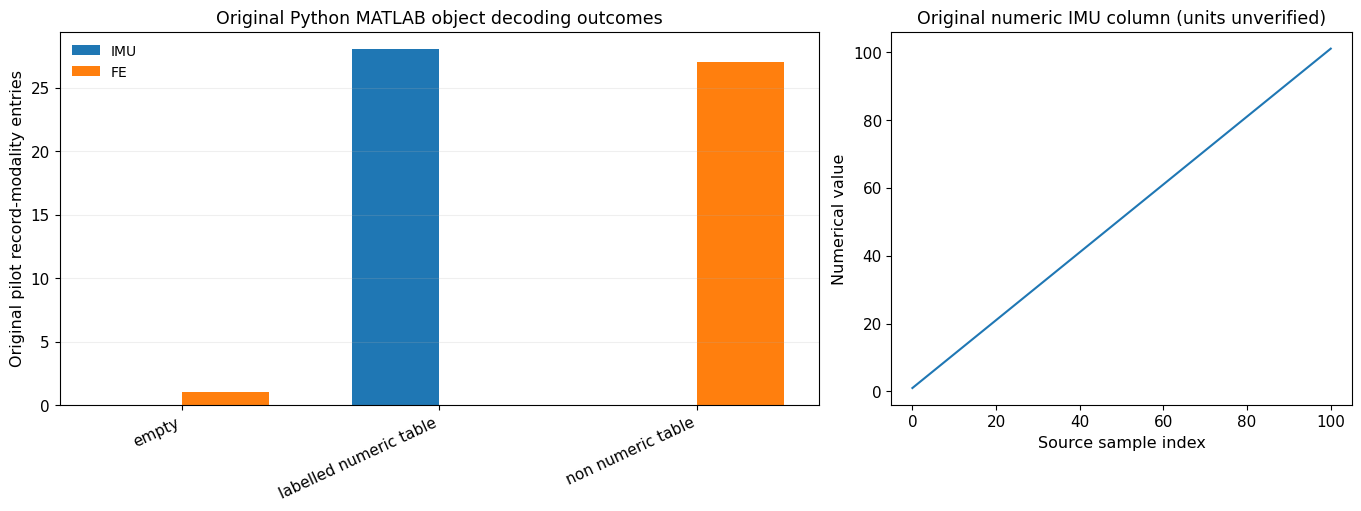

In [10]:
# ========= 08. Source-Object Reader Diagnostics and Real-Signal Plot =========

fig, ax = plt.subplots(
    1, 2, figsize=(13.5, 5),
    gridspec_kw={"width_ratios": [1.65, 1.0]},
    constrained_layout=True,
)
by_status = status.pivot(
    index="decode_status", columns="modality", values="count"
).fillna(0).astype(int).sort_index()
x = np.arange(len(by_status))
w = 0.34
for off, label in [(-0.5, "IMU"), (0.5, "FE")]:
    values = (
        by_status[label].to_numpy()
        if label in by_status else np.zeros(len(by_status))
    )
    ax[0].bar(x + off * w, values, w, label=label)
ax[0].set_xticks(x)
ax[0].set_xticklabels(
    [v.replace("_", " ") for v in by_status.index],
    rotation=25, ha="right"
)
ax[0].set_title("Original Python MATLAB object decoding outcomes")
ax[0].set_ylabel("Original pilot record-modality entries")
ax[0].legend(frameon=False)
ax[0].grid(axis="y", alpha=0.2)

imu_keys = [k for k in decoded if k[1] == "IMU"]
if imu_keys:
    real_values, original_names = decoded[imu_keys[0]]
    ax[1].plot(
        np.arange(real_values.shape[0]),
        real_values[:, 0], linewidth=1.5
    )
    ax[1].set_title("Original numeric IMU column (units unverified)")
    ax[1].set_xlabel("Source sample index")
    ax[1].set_ylabel("Numerical value")
else:
    ax[1].text(
        0.5, 0.5, "No source-labelled numerical IMU waveform",
        ha="center", va="center", transform=ax[1].transAxes
    )
    ax[1].set_title("Authentic numerical waveform availability")
    ax[1].set_xticks([])
    ax[1].set_yticks([])
save_figure(fig, output_dir / "05_python_first_decoder_diagnostics.png")
plt.show()

**09. Full-Source Export Decision**

The conversion function checks the strict pilot gate before processing all 40 participant files. The recorded pilot did not satisfy the expected numeric-array shapes, so **no full-cohort numeric export was produced**. The source table schema is now documented for a subsequent validated conversion approach.

In [11]:
# ======== 09. Guarded Python Conversion of All Original Essex Records ========

export_state = "BLOCKED_BY_PILOT"
export_error = None
export_zip = None
export_manifest = None
if allow_full:
    try:
        export_manifest, export_zip = export_full_source(
            load_from_mat, mat_dir, registry,
            raw_dir / "python_matio_full_export",
            Path("/content/native_essex_export.zip"),
        )
        export_state = "PYTHON_NUMERIC_EXPORT_CREATED"
    except Exception as exc:
        export_state = "FULL_EXPORT_FAILED_VALIDATION"
        export_error = f"{type(exc).__name__}: {str(exc)[:350]}"
print("Full original-source conversion:", export_state)
if export_error:
    print("Validation failure:", export_error)
if export_zip is not None:
    print("Private export ZIP:", export_zip)

if export_manifest is None:
    export_status = pd.DataFrame(columns=["modality", "status", "count"])
else:
    export_status = (
        export_manifest.groupby(["modality", "status"])
        .size().rename("count").reset_index()
    )
export_status.to_csv(
    output_dir / "05_python_first_full_export_status.csv", index=False
)
display(export_status)

Full original-source conversion: BLOCKED_BY_PILOT


,modality,status,count


**10. Results, Quality Gate and Research Outputs**

The experiment recovered source-linked numerical tables with `mat-io==1.0.1`, matched 28/28 original trial identities and identified `timestep`, 42 IMU signal columns and the FE `e1/e3` columns. Numeric model readiness remains unverified and the full export gate remains `BLOCKED_BY_PILOT`.

Eleven `05_*` files contain the record selection, decoder status, original column/index schemas, reader-error register, candidate metadata, diagnostic figure and Quality Gate JSON. The final code cell packages these outputs into a downloadable ZIP in Google Colab.

In [12]:
# ======= 10. Source-Backed Scientific Decision and Research Packaging ========

quality = {
    "source_article": ARTICLE_ID,
    "source_version": ARTICLE_VERSION,
    "source_sha256": source_hash["sha256"],
    "reader_package": "mat-io",
    "reader_version": version("mat-io"),
    "python_version": sys.version.split()[0],
    "pilot_subjects": list(PILOT_SUBJECTS),
    "source_records": int(len(registry)),
    "source_participants": int(registry["subject_id"].nunique()),
    "pilot_summary": pilot_results,
    "strict_expansion_gate": bool(allow_full),
    "full_source_export_state": export_state,
    "full_source_export_error": export_error,
    "full_export_sha256": sha256_file(export_zip) if export_zip else None,
    "source_integrity": "PASSED",
    "physical_units_verified": False,
    "fe_target_semantics_verified": False,
    "imu_fe_temporal_alignment_verified": False,
    "model_ready": False,
    "model_training_performed": False,
}
(output_dir / "05_python_first_quality_gate.json").write_text(
    json.dumps(quality, indent=2) + "\n", encoding="utf-8"
)
display(pd.DataFrame([{
    "pilot_records": pilot_results["sampled_original_records"],
    "reader_errors": pilot_results["reader_error_files"],
    "numeric_imu_tables": pilot_results["labelled_numeric_imu"],
    "numeric_fe_tables": pilot_results["labelled_numeric_fe"],
    "full_export_state": export_state,
    "regression_ready": False,
}]))
expected = [
    "05_python_first_pilot_selection.csv",
    "05_python_first_source_preflight.csv",
    "05_python_first_decode_audit.csv",
    "05_python_first_reader_errors.csv",
    "05_python_first_decoding_status.csv",
    "05_python_first_labelled_candidates.csv",
    "05_python_first_column_schema.csv",
    "05_python_first_index_schema.csv",
    "05_python_first_decoder_diagnostics.png",
    "05_python_first_full_export_status.csv",
    "05_python_first_quality_gate.json",
]
missing = [v for v in expected if not (output_dir / v).is_file()]
if missing:
    raise FileNotFoundError("Missing Python-first evidence: " + ", ".join(missing))
print("Scientific evidence files:", len(expected))
download_outputs_from_colab(
    folder="biomechanical_load_estimation/output", stage="05"
)

,pilot_records,reader_errors,numeric_imu_tables,numeric_fe_tables,full_export_state,regression_ready
0,28,0,28,0,BLOCKED_BY_PILOT,False


Scientific evidence files: 11
------------------------------------------------------------------------
Notebook stage: 05
Files packaged: 11
  + 05_python_first_column_schema.csv
  + 05_python_first_decode_audit.csv
  + 05_python_first_decoder_diagnostics.png
  + 05_python_first_decoding_status.csv
  + 05_python_first_full_export_status.csv
  + 05_python_first_index_schema.csv
  + 05_python_first_labelled_candidates.csv
  + 05_python_first_pilot_selection.csv
  + 05_python_first_quality_gate.json
  + 05_python_first_reader_errors.csv
  + 05_python_first_source_preflight.csv
Download ZIP from Colab Contents: /content/biomechanical_load_estimation_Stage_05_Outputs.zip
GitHub Commit/Push performed: NO
